In [1]:
%load_ext autoreload
%autoreload 2

# Plot the sensitivity of predictability to the initialization month
See corresponding development in `analysis/dev_draw_initmonths.ipynb`
- [x] simple plot of ppp regional mean with offset to align time of year
- [x] plot of difference between ppp from across initialization gaps at different leads/target months

In [2]:
import esm4ppe
import matplotlib.pyplot as plt
import calendar
import numpy as np
from dask.diagnostics import ProgressBar
import cartopy.crs as ccrs
import cartopy
import xarray as xr
from functions import *
import itertools

In [3]:
threshold = 0.235559205

## PPP from different init months with offset

In [4]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month')
variable = 'intpp'
region = 'pacific_T'
da = ds[variable].sel(region=region)

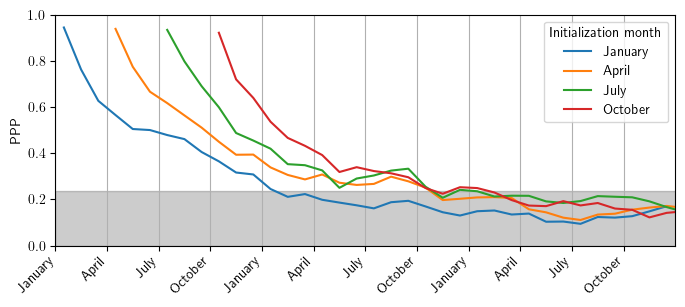

In [5]:
fig,ax = plt.subplots(figsize=(8,3))
for month in da['month']:
    if month==1:
        da = da.sel(lead=slice(0,36))
    offset = month-1
    ax.plot(da['lead']+offset-0.5,da.sel(month=month),label=calendar.month_name[month.values])
ax.set_xlim([0,36])
ax.set_ylim([0,1])
ax.set_ylabel('PPP')
step = 3
ax.set_xticks(np.arange(0,36,step))
ax.set_xticklabels(list(calendar.month_name)[1::step]*3,rotation=45,ha='right')
ax.grid(axis='x')
ax.legend(title='Initialization month')
ax.fill_between([0,120],threshold,color='k',alpha=0.2,zorder=0)
save_fig(fig,'fig.initmonth.ppp.'+region)

## PPP from different init months as a function of lead time, split up by regions

In [19]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month')
variable = 'tos'

In [20]:
regions = np.array([[None,'arctic',None],
           [None,'pacific_NoSubP','atlantic_NoSubP'],
           [None,'pacific_NoSubT','atlantic_NoSubT'],
           ['indian_T','pacific_T','atlantic_T'],
           ['indian_SoSubT','pacific_SoSubT','atlantic_SoSubT'],
           [None,'southern',None]])
regions_longname = {'arctic':r'Arctic',
                    'pacific_NoSubP':r'Pacific, 45 to 60$^\circ N$',
                    'atlantic_NoSubP':r'Atlantic, 45 to 60$^\circ N$',
                    'pacific_NoSubT':r'Pacific, 20 to 45$^\circ N$',
                    'atlantic_NoSubT':r'Atlantic, 20 to 45$^\circ N$',
                    'indian_T':r'Indian, 20$^\circ S$ to 20$^\circ N$',
                    'pacific_T':r'Pacific, 20$^\circ S$ to 20$^\circ N$',
                    'atlantic_T':r'Atlantic, 20$^\circ S$ to 20$^\circ N$',
                    'indian_SoSubT':r'Indian, 20 to 45$^\circ S$',
                    'pacific_SoSubT':r'Pacific, 20 to 45$^\circ S$',
                    'atlantic_SoSubT':r'Atlantic, 20 to 45$^\circ S$',
                    'southern':r'Southern'}

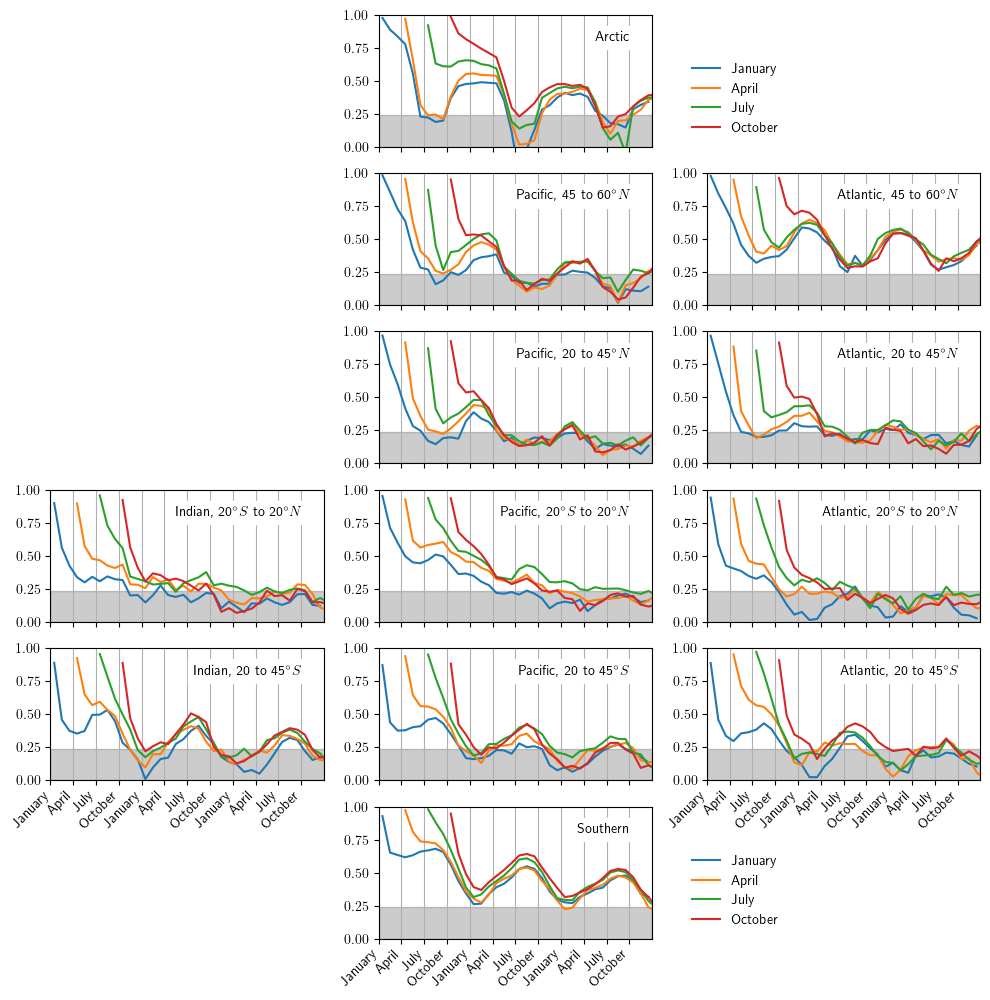

In [23]:
fig,axarr = plt.subplots(figsize=(12,12),nrows=6,ncols=3)
offset_bool = True
for i,j in itertools.product(range(6),range(3)):
    axnow = axarr[i,j]
    region = regions[i,j]
    if region is None:
        axnow.set_visible(False)
        continue
    else:
        danow = ds[variable].sel(region=region)

        for month in da['month']:
            if month==1:
                danow = danow.sel(lead=slice(0,36))
            
            if offset_bool:
                offset = month-1
            else:
                offset = 0
            axnow.plot(danow['lead']+offset+0.5,danow.sel(month=month),label=calendar.month_name[month.values])
        
        axnow.set_xlim([1,37])
        axnow.fill_between([1,37],threshold,color='k',alpha=0.2,zorder=0)
        axnow.set_ylim([0,1])
        step = 3
        axnow.set_xticks(np.arange(1,37,step))
        axnow.grid(axis='x')
        axnow.text(34,0.8,regions_longname[region],backgroundcolor='white',ha='right')
        if region in ['southern','indian_SoSubT','atlantic_SoSubT']:
            axnow.set_xticklabels(list(calendar.month_name)[1::step]*3,rotation=45,ha='right')
        else:
            axnow.set_xticklabels([ ])
            
        if region in ['arctic','southern']:
            axnow.legend(frameon=False,loc='lower left',bbox_to_anchor=(1.1,0))
figname = 'ppp_regions'
if offset_bool:
    figname+='_offset'
save_fig(fig,'fig.initmonth.'+figname+'.'+variable)

## PPP difference between successive initializations for a given target month

In [9]:
static = esm4ppe.open_static('intpp','monthly')
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')
masks = esm4ppe.get_masks('basin',static)

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [10]:
da = ds[variable]
compareinits = ['AprJan','JulApr','OctJul']
forecastmonth = np.arange(1,36+1)
xh = da['xh']
yh = da['yh']

mask = xr.zeros_like(da.sel(month=4,lead=1).squeeze())
mask[:]=np.nan
mask = mask.expand_dims({'compareinits':compareinits,'forecastmonth':forecastmonth})

drho = xr.zeros_like(da.sel(month=4,lead=1).squeeze())
drho[:]=np.nan
drho = drho.expand_dims({'compareinits':compareinits,'forecastmonth':forecastmonth})

for f in drho['forecastmonth']:
    for i,m in enumerate(ds['month'][1:]):
        if (f-m)<0:
            continue
        c=compareinits[i]
        rho_upper = da.sel(month=m,lead=f-m+1)
        rho_lower = da.sel(month=m-3,lead=f-(m-3)+1)
        
        mask_values = (rho_upper<threshold)
        mask.loc[{'compareinits':c,'forecastmonth':f}]=mask_values
        
        drho_values = rho_upper-rho_lower
        drho.loc[{'compareinits':c,'forecastmonth':f}]=drho_values

In [11]:
with ProgressBar():
    drho=drho.compute()
    mask=mask.compute()

[########################################] | 100% Completed | 15.04 s
[########################################] | 100% Completed | 5.74 sms


/tmp/ipykernel_2379896/830632382.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


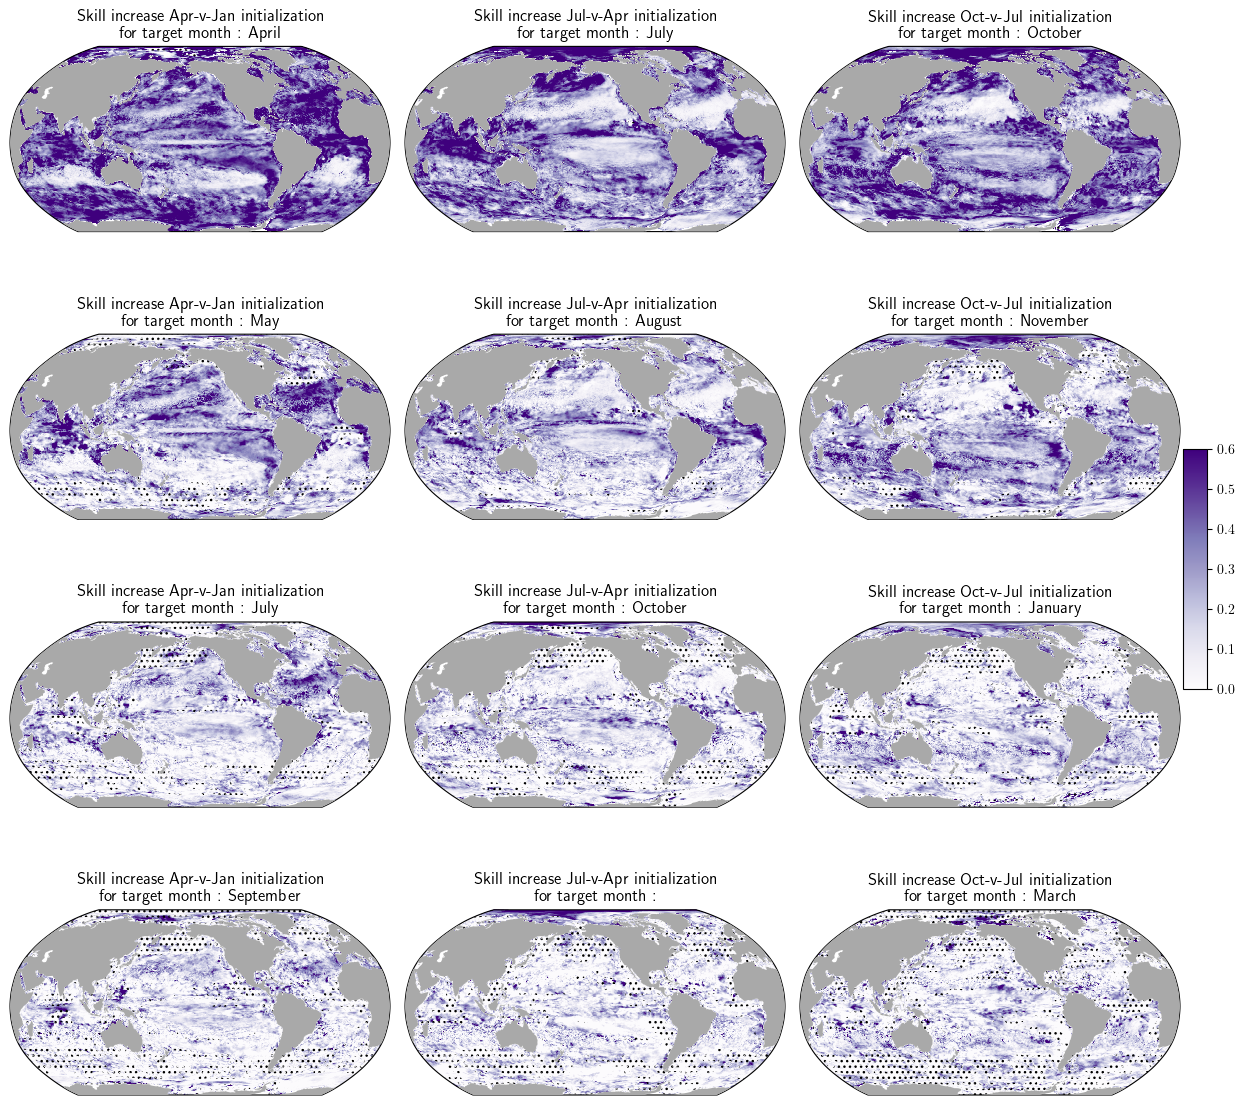

In [13]:
plt.rcParams['hatch.color'] = 'black'
leads = [0,1,3,5]
latterinitmonth = [4,7,10]
kw_args = {'cmap':'Purples','vmin':0,'vmax':0.6, 'transform':ccrs.PlateCarree()}
nm = len(drho['compareinits'])
nl = len(leads)
fig,axarr = plt.subplots(figsize=(4*nm, 3*nl), ncols=nm, nrows=nl, subplot_kw={'projection':ccrs.Robinson(central_longitude=-150)})
X,Y = static['geolon'],static['geolat']
for i,lead in enumerate(leads):
    for j,c in enumerate(drho['compareinits']):
        forecastmonth = latterinitmonth[j]+lead
        axnow = axarr[i,j]
        Z = drho.sel(compareinits=c,forecastmonth=forecastmonth)
        im = axnow.pcolormesh(X,Y,Z,**kw_args)
        title="Skill increase "+str(c.values)[:3]+"-v-"+str(c.values)[3:]+" initialization \n for target month : "+calendar.month_name[np.mod(forecastmonth,12)]
        axnow.set_title(title)
        axnow.add_feature(cartopy.feature.LAND,zorder=10,facecolor='darkgrey')
        Z = mask.sel(compareinits=c,forecastmonth=forecastmonth)
        axnow.contourf(X,Y,Z,1,hatches=['', '...'],alpha=0,transform=ccrs.PlateCarree())
position = [0.99,0.4,0.02,0.2]
axcb,imcb = add_colorbar(fig,im,position,orientation='vertical')
fig.tight_layout()
save_fig(fig,'fig.initmonth.deltaPPP.'+variable)

Positive values indicate that memory of the initialization date is retained. Looking down each column indicates how long that memory persists. Where positive values are retained in one column but not another indicates that there is a particular process occuring over that initialization gap that leads to a loss of memory, i.e. a predictability barrier. In a broad sense, it seems as though the deepening of the mixed layer is one such event, as evidenced by the unique strongly positive values in the subtropical and subpolar oceans for the initialization gaps corresponding to climatological deep MLDs (Apr-v-Jan and Oct-v-Jul). There are other interesting things happening in more specific regions, for example off the eastern African coast, in the northern Indian Ocean, and off the eastern Americas coast across the Jul-v-Apr gap.